- Monthly sales peaked in November 2011.
- Sales in the early months of 2011 were relatively low and stable, then rose noticeably from September.
- The drop in December is likely because the dataset ends in early December 2011, rather than a real decline in sales.
- The United Kingdom accounts for the largest share of revenue, at roughly 7.3 million, far ahead of all other countries.
- Among the top 10 countries, the Netherlands, Ireland (EIRE) and Germany follow, while the rest contribute much less.
- The dataset contains 4,339 customers, with an average of 4.3 orders per customer, about 93 days since the last purchase on average, and an average spend of about 2,054. The large standard deviations show that a small number of customers account for a large share of revenue.

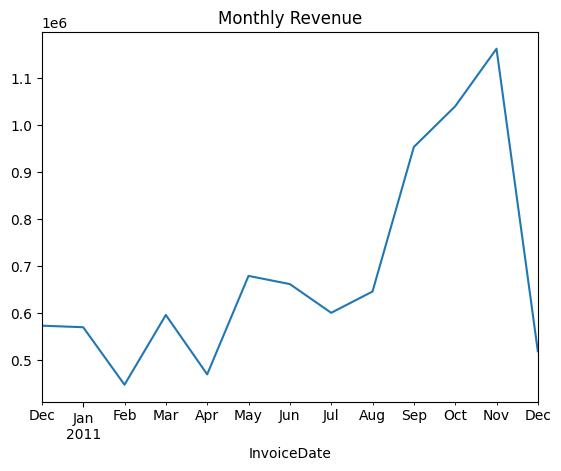

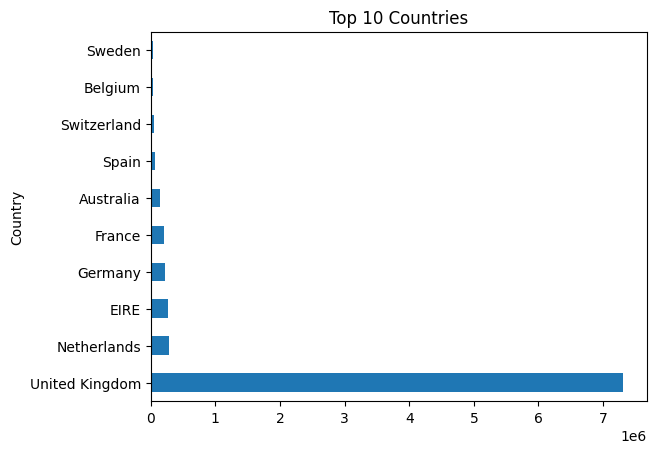

           Recency    Frequency       Monetary
count  4339.000000  4339.000000    4339.000000
mean     92.518322     4.271952    2053.793018
std     100.009747     7.705493    8988.248381
min       1.000000     1.000000       0.000000
25%      18.000000     1.000000     307.245000
50%      51.000000     2.000000     674.450000
75%     142.000000     5.000000    1661.640000
max     374.000000   210.000000  280206.020000


In [2]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_excel("Online Retail.xlsx")

df = df.dropna(subset=["CustomerID"])
df = df[df["Quantity"] > 0]
df["Revenue"] = df["Quantity"] * df["UnitPrice"]
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

monthly = df.groupby(df["InvoiceDate"].dt.to_period("M"))["Revenue"].sum()
monthly.plot(kind="line", title="Monthly Revenue")
plt.show()

df.groupby("Country")["Revenue"].sum().sort_values(ascending=False).head(10).plot(kind="barh", title="Top 10 Countries")
plt.show()

snapshot = df["InvoiceDate"].max() + pd.Timedelta(days=1)
rfm = df.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x: (snapshot - x.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("Revenue", "sum"))
print(rfm.describe())

In [1]:
from google.colab import files
uploaded = files.upload()
print(list(uploaded.keys()))

Saving Online Retail.xlsx to Online Retail.xlsx
['Online Retail.xlsx']
